In [1]:
import pandas as pd
import numpy as np


In [36]:
#game state variable

hitter_data = pd.read_csv("https://www.dropbox.com/scl/fi/8d4qem41fq1nx2oanbs9o/modeldata_hitter.csv?rlkey=gyk83a3tqpdlc2zqz2unokvms&st=b478bwpi&dl=1")

hitter_data["game_state"]=(
    hitter_data["inning"] +
    hitter_data["outs_when_up"]/10 +
    hitter_data["strikes"]/100
).round(5)

hitter_data["game_state"][100]

/var/folders/m_/clvqh96x4nj3lzfkfbbf_4gc0000gn/T/ipykernel_16436/2568530116.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  hitter_data["game_state"]=(


np.float64(7.11)

In [37]:
hitter_data.head(3)

,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,delta_run_exp_2.y,max_runexp.y,min_runexp.y,N.y,rowid.y,delta,challenge_hitter_lost,challenges_remaining,umpire_hp,game_state
0,FF,2026-09-02,92.7,-2.18,5.55,"Lord, Brad",645277,695418,NaN,called_strike,...,0.172977,0.173,0.172,397,19,0.260977,False,2,Dexter Kelley,2.0
1,ST,2026-09-02,82.4,-2.42,5.43,"Lord, Brad",671739,695418,NaN,called_strike,...,0.077000,0.077,0.077,2757,31,0.127000,False,2,Dexter Kelley,2.1
2,SI,2026-09-02,94.5,-2.18,5.37,"Lord, Brad",669221,695418,NaN,called_strike,...,0.038000,0.038,0.038,6547,49,0.081000,False,2,Dexter Kelley,2.2


In [4]:
hitter_data[["inning","strikes","outs_when_up","game_state"]].iloc[3]

inning          2.00
strikes         1.00
outs_when_up    2.00
game_state      2.12
Name: 3, dtype: float64

In [4]:
game_data = hitter_data.groupby(hitter_data["game_pk"]).size().reset_index(name = "challengeable_pitches")
game_data["challengeable_pitches"].describe()
hitter_data





,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,delta_run_exp_2.y,max_runexp.y,min_runexp.y,N.y,rowid.y,delta,challenge_hitter_lost,challenges_remaining,umpire_hp,game_state
0,FF,2026-09-02,92.7,-2.18,5.55,"Lord, Brad",645277,695418,NaN,called_strike,...,0.172977,0.173,0.172,397,19,0.260977,False,2,Dexter Kelley,2.00
1,ST,2026-09-02,82.4,-2.42,5.43,"Lord, Brad",671739,695418,NaN,called_strike,...,0.077000,0.077,0.077,2757,31,0.127000,False,2,Dexter Kelley,2.01
2,SI,2026-09-02,94.5,-2.18,5.37,"Lord, Brad",669221,695418,NaN,called_strike,...,0.038000,0.038,0.038,6547,49,0.081000,False,2,Dexter Kelley,2.02
3,SL,2026-09-02,86.3,-2.20,5.36,"Lord, Brad",669221,695418,NaN,called_strike,...,0.029000,0.029,0.029,3685,51,0.090000,False,2,Dexter Kelley,2.12
4,FF,2026-09-02,96.0,-2.31,5.42,"Lord, Brad",669221,695418,strikeout,called_strike,...,0.025000,0.025,0.025,2172,53,0.178000,False,2,Dexter Kelley,2.22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101760,SL,2026-03-30,84.2,-1.58,5.93,"Morillo, Juan",678009,666661,NaN,called_strike,...,0.024000,0.024,0.024,591,553,0.061000,False,2,Todd Tichenor,7.02
101761,SL,2026-03-30,86.3,-0.50,6.27,"Clarke, Taylor",650402,664199,NaN,called_strike,...,0.064000,0.064,0.064,2205,55,0.116000,False,2,Todd Tichenor,8.02
101762,ST,2026-03-30,81.9,-3.47,4.71,"Sewald, Paul",690993,623149,NaN,called_strike,...,0.085000,0.085,0.085,3836,7,0.141021,False,2,Todd Tichenor,9.00
101763,FF,2026-03-30,92.2,-3.49,4.46,"Sewald, Paul",682985,623149,NaN,called_strike,...,0.077000,0.077,0.077,2757,31,0.127000,False,2,Todd Tichenor,9.01


In [33]:
rng = np.random.default_rng(10404)
n_challengeable = rng.choice(game_data["challengeable_pitches"],size = 10000, replace=True)
delta_dist = rng.choice(hitter_data["delta_run_exp"].dropna(),size = 10000, replace = True)
def game_state_deltas(game_state,df = hitter_data,rng = rng): 
    values = df.loc[
        df["game_state"]==game_state,
        "delta_run_exp"
    ].dropna()
    return rng.choice(values)






In [19]:
##Actual Simulation
rng = np.random.default_rng(10404)
n_challengeable_per_game = hitter_data.groupby("game_pk").size()
valid_states = (
    hitter_data["delta_run_exp"].notna()
    & (hitter_data["inning"] <= 9)
)

filtered_data = hitter_data.loc[valid_states]
n_challengeable_per_game = filtered_data.groupby("game_pk").size()
state_deltas = (
    hitter_data.loc[valid_states].groupby("game_state")["delta_run_exp"].apply(lambda x: x.to_numpy()).to_dict()
)

n_games = 10000
games = []
sampleable_states = np.array(list(state_deltas.keys()))
for game_id in range(n_games):
    n_challengeable = rng.choice(n_challengeable_per_game.values)
    game_states = rng.choice(sampleable_states,
                             size = n_challengeable,
                             replace= True)
    for state in game_states:
        delta = rng.choice(state_deltas[state])
        games.append({
            "game_id": game_id,
            "game_state": state,
            "re_delta": delta
        })
simulation_df = pd.DataFrame(games)
simulation_df = simulation_df.sort_values(
    ["game_state", "game_id"],
    ascending=[False, True]
).reset_index(drop=True)


    

In [ ]:
game_id_sorted = simulation_df.sort_values(by=["game_state","game_id"], ascending = [True,True]).reset_index(drop=True)
game_id_sorted["challengeable_pitches_remaining"]=(game_id_sorted.groupby("game_id")["game_id"].transform("size")-game_id_sorted.groupby("game_id").cumcount())
game_id_grouping = game_id_sorted.groupby("game_id")
game_id_grouping.get_group(0)

In [25]:
n_challenges =1
values = game_id_sorted["re_delta"].dropna().to_numpy()
max_n = int(simulation_df.groupby("game_id").size().max())
Ex_total_n_k = np.zeros((max_n+1,n_challenges +1))
for n in range(1,max_n+1):
    for k in range(1,min(n,n_challenges)+1):
         Ex_total_n_k[n, k] = np.mean([
            max(
                x + Ex_total_n_k[n - 1, k - 1],
                Ex_total_n_k[n - 1, k]
            )
            for x in values
        
        ])
         


In [26]:
simulation_df = simulation_df.sort_values(
    ["game_id", "game_state"]
).reset_index(drop=True)

simulation_df["challengeable_pitches_remaining"] = (
    simulation_df.groupby("game_id").cumcount(ascending=False) + 1
)

simulation_df["challenge"] = False
simulation_df["stopping_threshold"] = np.nan

for game_id, indices in simulation_df.groupby("game_id").groups.items():
    challenges_left = n_challenges

    for idx in indices:
        n = int(simulation_df.loc[idx, "challengeable_pitches_remaining"])
        x = simulation_df.loc[idx, "re_delta"]

        if challenges_left == 0:
            continue

        # Expected value of saving the challenge
        threshold = (
            Ex_total_n_k[n - 1, challenges_left]
            - Ex_total_n_k[n - 1, challenges_left - 1]
        )

        simulation_df.loc[idx, "stopping_threshold"] = threshold

        # Challenge if current value exceeds the expected value of saving
        if x > threshold:
            simulation_df.loc[idx, "challenge"] = True
            challenges_left -= 1

In [29]:
simulation_df.loc[
    simulation_df["game_id"] == 12,
    [
        "game_id",
        "game_state",
        "re_delta",
        "challengeable_pitches_remaining",
        "stopping_threshold",
        "challenge"
    ]
]

,game_id,game_state,re_delta,challengeable_pitches_remaining,stopping_threshold,challenge
599,12,1.11,-0.077,33,0.084253,False
600,12,2.01,-0.061,32,0.082411,False
601,12,2.02,-0.187,31,0.080540,False
602,12,2.11,-0.071,30,0.078637,False
603,12,2.21,-0.062,29,0.076701,False
604,12,3.10,-0.041,28,0.074731,False
605,12,3.11,-0.107,27,0.072727,False
606,12,4.10,-0.041,26,0.070688,False
607,12,4.11,-0.069,25,0.068612,False
608,12,4.22,-0.154,24,0.066499,False


Matplotlib is building the font cache; this may take a moment.


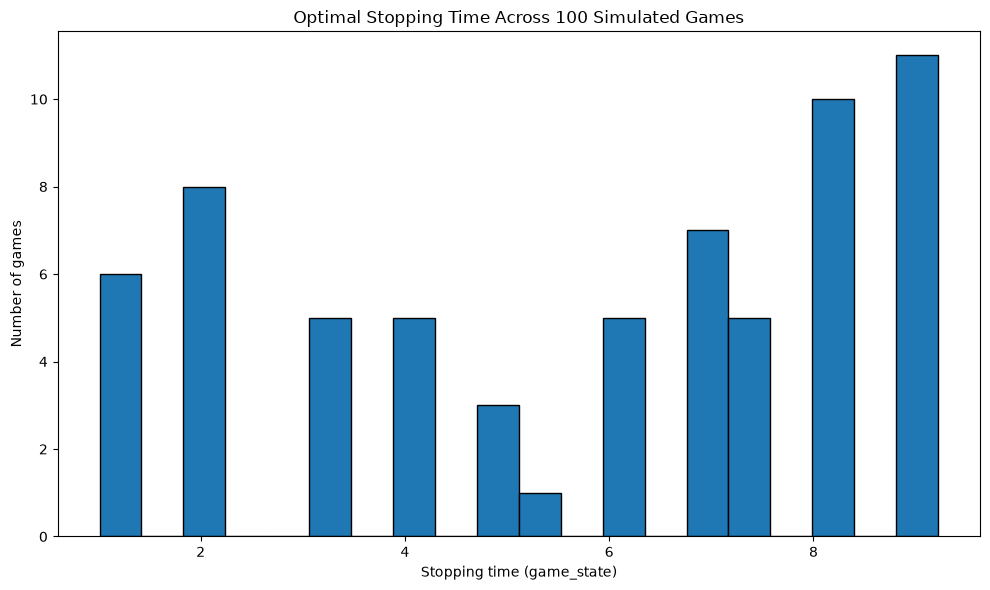

Games analyzed: 100
Games with a challenge: 66
Games without a challenge: 34


In [34]:
import matplotlib.pyplot as plt

# Select the first 100 simulated games
games_100 = simulation_df[
    simulation_df["game_id"].isin(
        sorted(simulation_df["game_id"].unique())[:100]
    )
].copy()

# Find the first opportunity where a challenge is made in each game
challenged = (
    games_100[games_100["challenge"]]
    .sort_values(["game_id", "game_state"])
    .drop_duplicates("game_id", keep="first")
)

# Include games where no challenge was made
game_ids = sorted(games_100["game_id"].unique())
stopping_states = (
    challenged.set_index("game_id")["game_state"]
    .reindex(game_ids)
)

# Plot histogram of stopping times
plt.figure(figsize=(10, 6))
plt.hist(stopping_states.dropna(), bins=20, edgecolor="black")
plt.xlabel("Stopping time (game_state)")
plt.ylabel("Number of games")
plt.title("Optimal Stopping Time Across 100 Simulated Games")
plt.tight_layout()
plt.show()

print("Games analyzed:", len(game_ids))
print("Games with a challenge:", stopping_states.notna().sum())
print("Games without a challenge:", stopping_states.isna().sum())

In [33]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 32.5 MB/s  0:00:00 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 44.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]
Note: you may need to restart the kernel to use updated packages.
